# OSSE: North Atlantic Hurricane

An observing system simulation experiment (OSSE) evaluates how well an observing system, real or planned, would observe a phenomenon, by sampling a high-resolution model simulation (the *nature run*) as the system would. This example is an OSSE of a **hurricane** in the 7-km [GEOS-5 Nature Run (G5NR)](https://gmao.gsfc.nasa.gov/global_mesoscale/7km-G5NR/). In late August of the Nature Run's second year, a simulated hurricane crosses the North Atlantic from near the Cape Verde Islands (about 15 N, 27 W on 20 August) to Nova Scotia (30 August). This example covers two days, 25 and 26 August, when the storm passes north of Puerto Rico and Hispaniola and begins to recurve to the north.

The observing systems are the same as in the [monsoon OSSE](RunOSSEMonsoon.ipynb): the atmospheric sounders on the current NOAA/NASA polar-orbiting satellites ([ATMS](../validation/ValidateImagerATMS.ipynb) and [CrIS](../validation/ValidateImagerCrIS.ipynb)) and two notional future sounders with finer resolution. Unlike the monsoon, whose features are scattered convective cells over land with a strong diurnal cycle, the features here are organized around one large storm over the ocean. Two kinds of features are defined:

* **cold cloud tops**, as in the monsoon OSSE, which outline the storm's central dense overcast and the convective cells of its rainbands; and
* **heavy precipitation**, which outlines its eyewall and rainbands, where microwave sounders sense the rain and ice beneath the cloud tops.

The experiment asks the same two questions about each feature:

1. **Is it observed?** Does a sounder's swath cover the feature?
2. **Is it resolved?** Is the part of the feature that is observed at least a few resolution elements (footprints or the spacing between them) across?

The steps are:

1. configure the scenario;
2. locate the storm in the coarsened (0.5 degree) Nature Run;
3. configure the Nature Run (7 km) around the storm;
4. define the features (cold cloud tops and heavy precipitation) in each 30-minute frame;
5. define the sensors;
6. compute the ground tracks (swaths) of the satellites over the study region with TAT-C;
7. determine whether each feature is observed and resolved by each sensor; and
8. generate a visualization and statistics.

The example is designed to run in a few minutes, after a one-time download of the Nature Run around the storm (about 100 MB, which takes several minutes). It requires the optional dependencies for OSSE examples (`pip install tatc[osse]`).

## Configure the Scenario

The study region (15-34 N, 77-58.5 W) is a box around the storm's track over the two days, at least 6 degrees from the storm center at all times, so that it contains the storm's clouds and rainbands as well as some convection of its environment. It is mostly ocean, with the northern coasts of Puerto Rico and Hispaniola and the Bahamas.

The Nature Run covers 15 May 2005 to 16 June 2007 and does not correspond to any real year. As in the monsoon OSSE, the satellite orbits (those of 25 August 2026, from operational element sets) are paired with the Nature Run on the same calendar date, here in its second year (2006), in which the storm occurs. Because the orbits are sun-synchronous, the local solar times at which they observe do not depend on the date.

In [1]:
from datetime import datetime, timedelta, timezone
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import box

DATA_DIR = Path("data") / "osse"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# study region: a box around the storm's track over the two days
domain = box(-77, 15, -58.5, 34)
# the simulated orbits and the nature run (the same calendar date in the Nature Run's second year)
start = datetime(2026, 8, 25, tzinfo=timezone.utc)
nature_start = start.replace(year=2006)
duration = timedelta(days=2)
frame_duration = timedelta(minutes=30)  # the Nature Run's time-averaging interval
n_frames = int(duration / frame_duration)

## Locate the Storm

The full-resolution (7 km) Nature Run is too large to search a whole ocean basin over a season. Its coarsened collections (0.5 degrees, hourly) are about 200 times smaller per time step and suffice to find and track storms: this storm was found as the deepest low in the sea-level pressure (`slp`) of the coarsened collection over the North Atlantic around 25 August. Here, the storm center at each hour is the minimum sea-level pressure in the study region, and the storm's strength is given by the minimum pressure and the maximum 10 m wind speed (`u10m`, `v10m`) in the region. Both are smoothed by the coarse grid, so the storm at full resolution is somewhat deeper and stronger.

In [2]:
import xarray as xr

G5NR_URL = "https://opendap.nccs.nasa.gov/dods/OSSE/G5NR/Ganymed/7km"
COARSE_URL = f"{G5NR_URL}/0.5000_deg/inst/inst01hr_2d_met1_Cx"


def naive(time):
    """A time without its time zone, as the Nature Run's time coordinate."""
    return time.replace(tzinfo=None)


coarse_file = DATA_DIR / f"g5nr_hurricane_coarse_{nature_start:%Y%m%d}_{duration.days}d.nc"
if not coarse_file.exists():
    minx, miny, maxx, maxy = domain.bounds
    with xr.open_dataset(COARSE_URL) as remote:
        remote[["slp", "u10m", "v10m"]].sel(
            time=slice(naive(nature_start), naive(nature_start + duration)),
            lon=slice(minx, maxx),
            lat=slice(miny, maxy),
        ).load().to_netcdf(coarse_file)
coarse = xr.load_dataset(coarse_file)

# the storm center (the minimum sea-level pressure in the study region) and strength at each hour
slp = coarse.slp.stack(cell=("lat", "lon"))
center = slp.isel(cell=slp.argmin("cell"))
track = pd.DataFrame(
    {
        "lat": center.lat.values,
        "lon": center.lon.values,
        "min_slp_hpa": center.values / 100,
        "max_wind_ms": np.hypot(coarse.u10m, coarse.v10m).max(("lat", "lon")).values,
    },
    index=pd.DatetimeIndex(coarse.time.values, name="time"),
)
track.iloc[::6].round(1)

,lat,lon,min_slp_hpa,max_wind_ms
time,,,,
2006-08-25 00:00:00,21.0,-64.5,962.900024,39.299999
2006-08-25 06:00:00,21.5,-66.0,960.099976,41.500000
2006-08-25 12:00:00,22.0,-67.5,962.500000,39.200001
2006-08-25 18:00:00,23.0,-68.5,963.000000,40.200001
2006-08-26 00:00:00,23.5,-69.5,958.700012,42.000000
2006-08-26 06:00:00,24.5,-70.0,958.299988,40.599998
2006-08-26 12:00:00,25.5,-70.5,955.700012,41.500000
2006-08-26 18:00:00,27.0,-70.5,956.599976,44.799999
2006-08-27 00:00:00,28.0,-71.0,951.799988,41.799999


## Configure the Nature Run

The full-resolution (0.0625 degree, about 7 km) fields are needed only around the storm, so only the study region is requested. As in the monsoon OSSE, this example uses the single-level, 30-minute time-averaged diagnostics, and reads the upwelling longwave flux at the top of the atmosphere (`lwtup`), a proxy for cloud-top temperature, the total precipitation rate (`prectot`), and its convective part (`preccon`). In a hurricane, much of the rain falls from the storm's resolved circulation rather than from parameterized convection, so the features use the total rate. The fields are requested in 12-hour chunks, each checked for a field of zeros, which the server has been found to return in place of a field for some large requests, and saved in a local `data/osse` directory, so later runs are fast.

In [3]:
NATURE_URL = f"{G5NR_URL}/0.0625_deg/tavg/tavg30mn_2d_met3_Nx"
GRID_SIZE = 0.0625  # deg
VARIABLES = ["lwtup", "prectot", "preccon"]
CHUNK = timedelta(hours=12)


def fetch_chunk(remote, chunk_start):
    """One chunk of the Nature Run over the study region, retried if the server returns a field of zeros."""
    minx, miny, maxx, maxy = domain.bounds
    for attempt in range(4):
        chunk = remote[VARIABLES].sel(
            time=slice(naive(chunk_start), naive(chunk_start + CHUNK - timedelta(seconds=1))),
            lon=slice(minx, maxx),
            lat=slice(miny, maxy),
        ).load()
        if float((chunk["lwtup"] == 0).mean()) < 0.5:
            return chunk
    raise RuntimeError(f"the server returned a field of zeros for {chunk_start}")


nature_file = DATA_DIR / f"g5nr_hurricane_{nature_start:%Y%m%d}_{duration.days}d.nc"
if not nature_file.exists():
    with xr.open_dataset(NATURE_URL) as remote:
        chunks = [fetch_chunk(remote, nature_start + k * CHUNK) for k in range(int(duration / CHUNK))]
    xr.concat(chunks, "time").to_netcdf(nature_file)
nature = xr.load_dataset(nature_file)
assert nature.sizes["time"] == n_frames
assert float((nature["lwtup"] == 0).mean()) == 0
# each time stamp is the middle of its 30-minute averaging interval
assert (nature.time.values[0] - np.datetime64(naive(nature_start))) == np.timedelta64(15, "m")
nature

<xarray.Dataset> Size: 104MB
Dimensions:  (time: 96, lat: 305, lon: 297)
Coordinates:
  * time     (time) datetime64[ns] 768B 2006-08-25T00:15:00 ... 2006-08-26T23...
  * lat      (lat) float64 2kB 15.0 15.06 15.12 15.19 ... 33.81 33.88 33.94 34.0
  * lon      (lon) float64 2kB -77.0 -76.94 -76.88 ... -58.62 -58.56 -58.5
Data variables:
    lwtup    (time, lat, lon) float32 35MB 172.8 172.8 173.4 ... 291.4 290.9
    prectot  (time, lat, lon) float32 35MB 1.875e-05 1.425e-05 ... 1.246e-06
    preccon  (time, lat, lon) float32 35MB 1.785e-05 1.389e-05 ... 1.241e-06
Attributes:
    title:                2d,30-Minute,Time-Averaged,Single-Level,Full Resolu...
    Conventions:          COARDS\nGrADS
    dataType:             Grid
    history:              Mon Sep 28 12:21:13 EDT 2026 : imported by GrADS Da...
    extra_das_attribute:  This is an example of metadata added using a supple...

## Define the Environmental Features

Features are contiguous patches of grid cells of one of two kinds:

* **cold cloud top**: an upwelling longwave flux below that of a 220 K blackbody (about 133 W m-2), as in the monsoon OSSE; and
* **heavy precipitation**: a total precipitation rate above `PRECIP_THRESHOLD` (10 mm/h).

Each patch in each frame is a feature, and, as in the monsoon OSSE, patches smaller than the Nature Run's effective resolution (`EFFECTIVE_RESOLUTION_KM`, four grid spacings or 28 km) are discarded. A large patch of cold cloud tops may contain several patches of heavy precipitation, so the two kinds overlap.

For each feature, the notebook records its area, the diameter of a circle of the same area (its size), the area-weighted centroid, its coldest flux, its highest and total precipitation rates, and its distance from the storm center at the middle of its frame (interpolated from the hourly track). Features within `STORM_RADIUS_KM` (500 km) of the center are attributed to the storm and the others to its environment.

In [4]:
import scipy.ndimage as ndi

from tatc.constants import EARTH_MEAN_RADIUS

THRESHOLD = 5.67037e-8 * 220**4  # W m-2, the upwelling longwave flux of a 220 K blackbody
PRECIP_THRESHOLD = 10 / 3600  # kg m-2 s-1 (10 mm/h)
EFFECTIVE_RESOLUTION_KM = 4 * 7  # km, several grid spacings (Gelaro et al., 2015); smaller features are not resolved
STORM_RADIUS_KM = 500  # km, features within this distance of the storm center are attributed to the storm
KINDS = {
    "cold cloud top": lambda frame: frame["lwtup"].values < THRESHOLD,
    "heavy precipitation": lambda frame: frame["prectot"].values > PRECIP_THRESHOLD,
}


def find_features(nature, kind):
    """The features of a kind (contiguous patches at least EFFECTIVE_RESOLUTION_KM in size) in each frame."""
    lon, lat = nature.lon.values, nature.lat.values
    lon2d, lat2d = np.meshgrid(lon, lat)
    cell_area = (EARTH_MEAN_RADIUS * np.radians(GRID_SIZE)) ** 2 * np.cos(np.radians(lat2d))  # m^2

    records, polygons = [], []
    for frame in range(nature.sizes["time"]):
        fields = nature.isel(time=frame)
        lwtup, prectot = fields["lwtup"].values, fields["prectot"].values
        labels, n_labels = ndi.label(KINDS[kind](fields))  # contiguous cells of the kind
        if n_labels == 0:
            continue
        ids = np.arange(1, n_labels + 1)
        area = ndi.sum(cell_area, labels, ids)
        n_cells = ndi.sum(np.ones_like(lwtup), labels, ids).astype(int)
        # polygons are the unions of the cells, which are centered on the grid points
        j, i = np.nonzero(labels)
        order = np.argsort(labels[j, i], kind="stable")
        j, i = j[order], i[order]
        cells = shapely.box(
            lon[i] - GRID_SIZE / 2, lat[j] - GRID_SIZE / 2, lon[i] + GRID_SIZE / 2, lat[j] + GRID_SIZE / 2
        )
        for k, cluster in enumerate(np.split(cells, np.cumsum(n_cells)[:-1])):
            records.append(
                {
                    "frame": frame,
                    "kind": kind,
                    "n_cells": n_cells[k],
                    "area_km2": area[k] / 1e6,
                    "lon": ndi.sum(cell_area * lon2d, labels, ids[k]) / area[k],
                    "lat": ndi.sum(cell_area * lat2d, labels, ids[k]) / area[k],
                    "min_lwtup": ndi.minimum(lwtup, labels, ids[k]),
                    "max_prectot_mmh": ndi.maximum(prectot, labels, ids[k]) * 3600,
                    "tot_prectot": ndi.sum(prectot * cell_area, labels, ids[k]),
                }
            )
            polygons.append(shapely.union_all(cluster))

    features = gpd.GeoDataFrame(records, geometry=polygons, crs="EPSG:4326")
    features["diameter_km"] = np.sqrt(4 * features.area_km2 / np.pi)  # of a circle of equal area
    return features[features.diameter_km >= EFFECTIVE_RESOLUTION_KM]


features = pd.concat([find_features(nature, kind) for kind in KINDS], ignore_index=True)
features["time"] = start + features.frame * frame_duration

# distance (great circle) from the storm center at the middle of the frame, interpolated from the hourly track
frame_middle = (nature.time.values[features.frame] - track.index.values[0]) / np.timedelta64(1, "h")
track_hours = (track.index.values - track.index.values[0]) / np.timedelta64(1, "h")
center_lat = np.radians(np.interp(frame_middle, track_hours, track.lat))
center_lon = np.radians(np.interp(frame_middle, track_hours, track.lon))
lat, lon = np.radians(features.lat), np.radians(features.lon)
features["storm_distance_km"] = (
    EARTH_MEAN_RADIUS / 1e3
    * np.arccos(np.clip(np.sin(lat) * np.sin(center_lat) + np.cos(lat) * np.cos(center_lat) * np.cos(lon - center_lon), -1, 1))
)
features["region"] = np.where(features.storm_distance_km < STORM_RADIUS_KM, "storm", "environment")
features.groupby(["kind", "region"]).agg(
    features=("frame", "size"),
    median_diameter_km=("diameter_km", "median"),
    max_diameter_km=("diameter_km", "max"),
    max_prectot_mmh=("max_prectot_mmh", "max"),
).round(1)

features  median_diameter_km  \
kind                region                                      
cold cloud top      environment       190                51.7   
                    storm             355                56.4   
heavy precipitation environment        51                31.7   
                    storm             517                49.2   

                                 max_diameter_km  max_prectot_mmh  
kind                region                                         
cold cloud top      environment            115.3            182.2  
                    storm                  483.0            102.0  
heavy precipitation environment             46.0            209.8  
                    storm                  215.1            134.3

## Define the Sensors

The platforms, swaths, and sensors are those of the monsoon OSSE (see there for their basis): ATMS and CrIS on Suomi NPP, NOAA-20, and NOAA-21, with the scan parameters fitted to NOAA-20 data in the validation notebooks, and the notional future microwave (MW) and infrared (IR) sounders with finer resolution, sharing the ATMS and CrIS swaths. Here the element sets are those of 25 August 2026.

In [5]:
from tatc.schemas import GeneralPerturbationsOrbit, PointedInstrument, Satellite
from tatc.utils import VelocityFrame, compute_along_track_field_of_view

# element sets (epoch 2026-08-25 00:00 UTC) from the JPSS TLE-AUX archive, as in the validation notebooks
tles = {
    "Suomi NPP": [
        "1 37849U 11061A   26237.00000000  .00000048  00000-0  22799-4 0  2729",
        "2 37849 098.7980 177.4149 0002756 116.4369 275.9805 14.19529488768207",
    ],
    "NOAA-20": [
        "1 43013U 17073A   26237.00000000  .00000082  00000-0  38818-4 0  2185",
        "2 43013 098.7794 175.8588 0001924 083.1912 240.0420 14.19522547454239",
    ],
    "NOAA-21": [
        "1 54234U 22150A   26237.00000000  .00000066  00000-0  31364-4 0  9878",
        "2 54234 098.7078 174.6381 0001971 035.6178 125.9881 14.19546491196315",
    ],
}
orbits = {name: GeneralPerturbationsOrbit.from_tle(tle) for name, tle in tles.items()}

# scan parameters fitted to NOAA-20 data in the ATMS and CrIS validation notebooks: the number of scan positions,
# their spacing (deg), and the roll angle (deg, positive to the left); both scan perpendicular to the inertial velocity
scans = {
    "ATMS": {"positions": 96, "spacing": 1.112, "roll": 0.04},
    "CrIS": {"positions": 30, "spacing": 3.334, "roll": -0.093},
}
TIME_STEP = 30  # s, of the ground track


def swath_instrument(name):
    """A rectangular view spanning the scan positions, tailored to the time step (as validated for ATMS and CrIS)."""
    scan = scans[name]
    field_of_regard = (scan["positions"] - 1) * scan["spacing"]
    return PointedInstrument(
        name=name,
        field_of_regard=field_of_regard,
        cross_track_field_of_view=field_of_regard,
        along_track_field_of_view=compute_along_track_field_of_view(
            orbits["NOAA-20"].get_mean_altitude(), TIME_STEP, orbits["NOAA-20"].get_inclination()
        ),
        roll_angle=scan["roll"],
        is_rectangular=True,
        velocity_frame=VelocityFrame.INERTIAL,
    )


satellites = [
    Satellite(name=name, orbit=orbit, instruments=[swath_instrument("ATMS"), swath_instrument("CrIS")])
    for name, orbit in orbits.items()
]

REFERENCE_RANGE_KM = 830  # nominal slant range at nadir (altitude), at which the nominal resolutions apply
# angular spacing (deg) of the samples of each scan, fitted to NOAA-20 data in the validation notebooks: the ATMS scan
# positions and the pitch of the CrIS 3 x 3 array of views
SAMPLING_DEG = {"ATMS": scans["ATMS"]["spacing"], "CrIS": 1.092}
# sensors: the scan (swath) they share, and their horizontal resolution at nadir (km)
sensors = pd.DataFrame(
    [
        {"sensor": "ATMS", "swath": "ATMS", "horizontal_km": 32},
        {"sensor": "CrIS", "swath": "CrIS", "horizontal_km": 14},
        {"sensor": "Future MW", "swath": "ATMS", "horizontal_km": 10},
        {"sensor": "Future IR", "swath": "CrIS", "horizontal_km": 3},
    ]
).set_index("sensor")
# sample spacing at nadir (km): that of the heritage sensor, scaled for the future sensors in proportion to their footprint
heritage_km = sensors.horizontal_km[sensors.swath].values
sensors["sampling_km"] = REFERENCE_RANGE_KM * np.radians(sensors.swath.map(SAMPLING_DEG)) * sensors.horizontal_km / heritage_km

def sensor_instrument(sensor):
    """The swath instrument of a sensor with its pixels (for its sample sizes, see `compute_sample_sizes`): pixels
    spaced by the angle that the sample spacing subtends at nadir from the reference range (enough to span the
    swath), each with the instantaneous field of view that its horizontal resolution subtends, along and across
    track."""
    row = sensors.loc[sensor]
    swath = swath_instrument(row.swath)
    ifov = np.degrees(2 * np.arctan(row.horizontal_km / 2 / REFERENCE_RANGE_KM))
    spacing = np.degrees(row.sampling_km / REFERENCE_RANGE_KM)
    pixels = round(swath.cross_track_field_of_view / spacing)
    # the oversampling makes each pixel's field of view ifov (negative: a gap between pixels)
    return PointedInstrument(
        **swath.model_dump(
            exclude={
                "cross_track_field_of_view",
                "along_track_field_of_view",
                "cross_track_pixels",
                "cross_track_oversampling",
                "along_track_oversampling",
            }
        ),
        cross_track_field_of_view=pixels * spacing,
        along_track_field_of_view=spacing,
        cross_track_pixels=pixels,
        cross_track_oversampling=1 - spacing / ifov,
        along_track_oversampling=1 - spacing / ifov,
    )


sensors.round(1)

,swath,horizontal_km,sampling_km
sensor,,,
ATMS,ATMS,32,16.1
CrIS,CrIS,14,15.8
Future MW,ATMS,10,5.0
Future IR,CrIS,3,3.4


## Compute the Ground Tracks

`collect_ground_track` returns the footprint of each instrument at each time step, clipped to the study region (the `mask`), which are tabulated per frame and combined (`swaths`) to find the area each swath covers in each frame.

In [6]:
from tatc.analysis import collect_ground_track


def collect_tracks(satellites, duration):
    """The footprint of every instrument of the satellites at each time step over a duration from start, clipped to the
    study region, with its frame."""
    times = [start + timedelta(seconds=TIME_STEP * (i + 0.5)) for i in range(int(duration.total_seconds() // TIME_STEP))]
    tracks = collect_ground_track(satellites, times, instrument_index=None, mask=domain)
    tracks = tracks[tracks.valid_obs].reset_index(drop=True)
    tracks["geometry"] = shapely.force_2d(tracks.geometry.values)
    tracks["frame"] = ((tracks.time - start) // frame_duration).astype(int)
    return tracks


tracks = collect_tracks(satellites, duration)
# the area swept by each swath (ATMS or CrIS) in each frame
swaths = tracks.groupby(["frame", "instrument"]).geometry.agg(shapely.union_all)
tracks.groupby(["satellite", "instrument"]).agg(footprints=("time", "size"), first=("time", "min"), last=("time", "max"))

footprints                     first  \
satellite instrument                                         
NOAA-20   ATMS                96 2026-08-25 05:55:45+00:00   
          CrIS                92 2026-08-25 05:55:45+00:00   
NOAA-21   ATMS                80 2026-08-25 05:00:15+00:00   
          CrIS                69 2026-08-25 05:00:15+00:00   
Suomi NPP ATMS                99 2026-08-25 05:36:45+00:00   
          CrIS                94 2026-08-25 05:36:45+00:00   

                                          last  
satellite instrument                            
NOAA-20   ATMS       2026-08-26 18:37:15+00:00  
          CrIS       2026-08-26 18:37:15+00:00  
NOAA-21   ATMS       2026-08-26 17:41:45+00:00  
          CrIS       2026-08-26 17:41:45+00:00  
Suomi NPP ATMS       2026-08-26 18:18:15+00:00  
          CrIS       2026-08-26 18:18:15+00:00

## Compute Observability and Resolution

As in the monsoon OSSE, a feature is **observed** by a swath if the swath footprint of some time step in its frame overlaps it, a **look** is one satellite's view of the part of a feature inside its swath, and a feature is **resolved** if its viewed part spans at least `RESOLUTION_FACTOR` (two) resolution elements at its best look. TAT-C's `collect_feature_observations` collects the looks at features that exist for a period of time (here, each feature's frame), with the viewing geometry of each. The resolution element is the larger of a sensor's pixel and the spacing between its pixels, projected onto the ground at the look by TAT-C's `compute_sample_sizes` along and across track (see the monsoon OSSE), with its size measured as the diameter of a circle of the same area (`ELEMENT_AXIS`).

In [7]:
from tatc.analysis import collect_feature_observations, compute_sample_sizes

RESOLUTION_FACTOR = 2  # a feature is resolved if its viewed part spans at least this many resolution elements
ELEMENT_AXIS = "equivalent"  # the size of a resolution element: "equivalent" (diameter of equal area) or "cross-track"
AXES = ["equivalent", "cross-track"]

def collect_looks(satellites, duration, features):
    """The looks at the features (see `collect_feature_observations`): each satellite's view of the part of each
    feature inside its swath in the feature's frame, at the time of the footprint that covers most of it, with the
    size of the viewed part and the slant range and zenith angle at its centroid."""
    times = [start + timedelta(seconds=TIME_STEP * (i + 0.5)) for i in range(int(duration.total_seconds() // TIME_STEP))]
    looks = collect_feature_observations(
        features.assign(start=features.time, end=features.time + frame_duration), satellites, times
    )
    looks["viewed_km"] = np.sqrt(4 * looks.viewed_fraction * features.area_km2.values[looks.feature] / np.pi)
    looks["range_m"], looks["zenith"] = looks.sat_range, 90 - looks.sat_alt
    return looks


def assess(looks, features, satellites):
    """Whether each sensor observes and resolves each feature, from its best look."""
    results = []
    for sensor, row in sensors.iterrows():
        # the sizes of the sensor's samples at its looks, flown on the same satellites
        sensor_satellites = [
            satellite.model_copy(update={"instruments": [sensor_instrument(sensor)]}) for satellite in satellites
        ]
        sensor_looks = compute_sample_sizes(looks[looks.instrument == row.swath], sensor_satellites)
        # the resolution element is the larger of a sample and the spacing between samples (km), along and across track
        along = np.maximum(sensor_looks.sample_along, sensor_looks.spacing_along) / 1e3
        cross = np.maximum(sensor_looks.sample_cross, sensor_looks.spacing_cross) / 1e3
        for axis, element_km in {"equivalent": np.sqrt(along * cross), "cross-track": cross}.items():
            sensor_looks[f"elements ({axis})"] = sensor_looks.viewed_km / element_km
            if axis == ELEMENT_AXIS:
                sensor_looks["element_km"] = element_km
        # the best look at each feature: the one whose viewed part spans the most resolution elements
        best = sensor_looks.loc[sensor_looks.groupby("feature")[f"elements ({ELEMENT_AXIS})"].idxmax()].set_index("feature")
        result = features[["frame", "kind", "region", "diameter_km", "area_km2", "tot_prectot"]].copy()
        result["sensor"] = sensor
        result["looks"] = sensor_looks.groupby("feature").size().reindex(result.index, fill_value=0)
        result["observed"] = result.looks > 0
        result = result.join(best[["satellite", "zenith", "viewed_fraction", "viewed_km", "element_km"]])
        for axis in AXES:
            result[f"elements ({axis})"] = sensor_looks.groupby("feature")[f"elements ({axis})"].max()
        result["resolved"] = result[f"elements ({ELEMENT_AXIS})"] >= RESOLUTION_FACTOR
        results.append(result)
    return pd.concat(results).reset_index().rename(columns={"index": "feature"})


looks = collect_looks(satellites, duration, features)
results = assess(looks, features, satellites)
results.groupby(["kind", "sensor"])[["observed", "resolved"]].sum().unstack("kind")

observed                           resolved  \
kind      cold cloud top heavy precipitation cold cloud top   
sensor                                                        
ATMS                  84                  55             20   
CrIS                  71                  45             46   
Future IR             71                  45             70   
Future MW             84                  55             69   

                               
kind      heavy precipitation  
sensor                         
ATMS                       16  
CrIS                       27  
Future IR                  44  
Future MW                  42

## Generate a Visualization

The figure shows the heavy precipitation features of one frame, the one with the most such features whose status differs between the sensors, colored by whether each sensor resolves them (blue), observes but does not resolve them (orange), or does not observe them (faded, outside the swath). The underlying image is the Nature Run's upwelling longwave flux, whose dark areas are cold cloud tops, and the line is the storm's track over the two days, with its center in the frame marked.

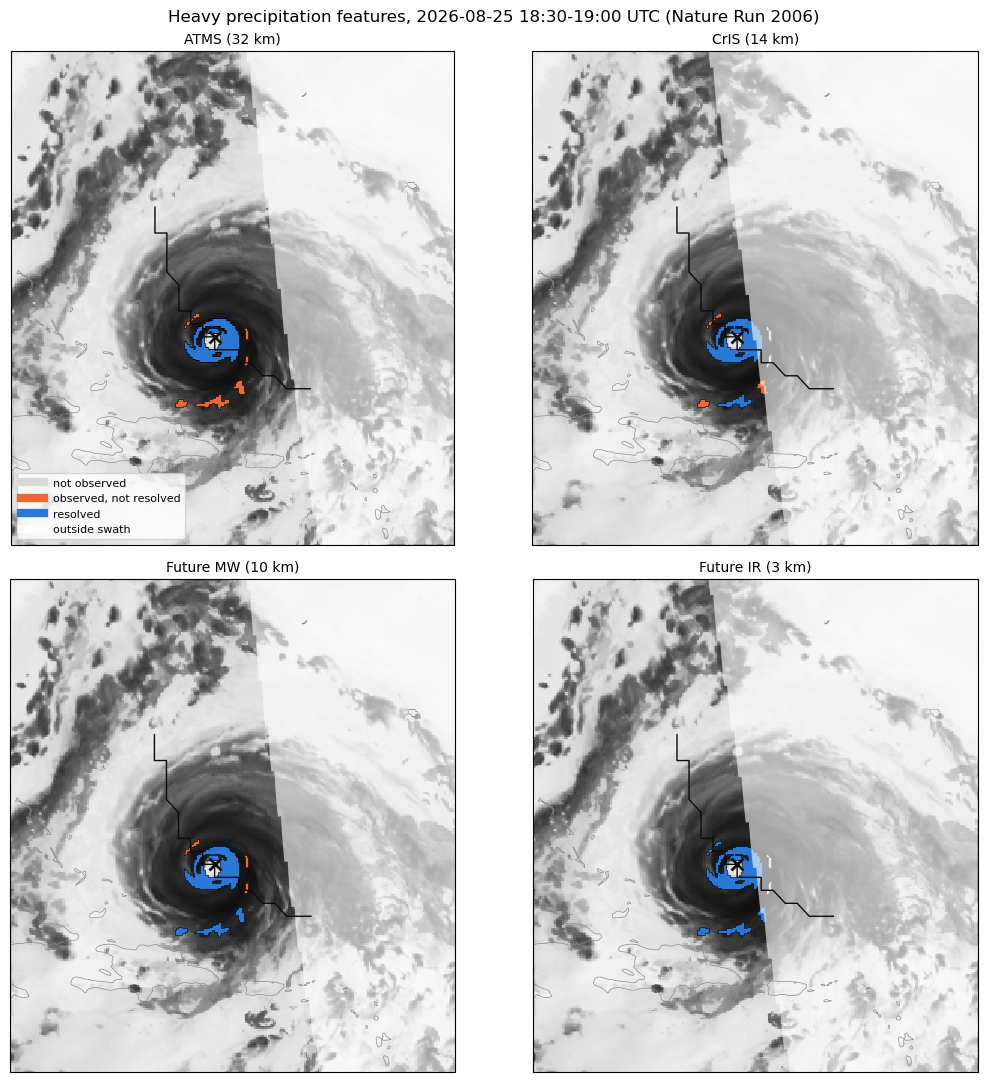

In [8]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

KIND = "heavy precipitation"
# the frame with the most features of the kind whose status (not observed, observed, or resolved) differs between the sensors
of_kind = results[results.kind == KIND]
status = of_kind.observed.astype(int) + of_kind.resolved.astype(int)
example = (status.groupby([of_kind.frame, of_kind.feature]).nunique() > 1).groupby("frame").sum().idxmax()
example_time = start + example * frame_duration
example_center = track.iloc[np.abs(track.index - pd.Timestamp(nature.time.values[example])).argmin()]
STATUS = {"not observed": "#d9d8d3", "observed, not resolved": "#eb6834", "resolved": "#2a78d6"}

fig, axes = plt.subplots(2, 2, figsize=(11, 11), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, sensor in zip(axes.ravel(), sensors.index):
    background = nature["lwtup"].isel(time=example)
    ax.pcolormesh(background.lon, background.lat, background, cmap="Greys_r", vmin=100, vmax=320, shading="auto", transform=ccrs.PlateCarree())
    members = of_kind[(of_kind.sensor == sensor) & (of_kind.frame == example)]
    member_status = np.where(members.resolved, "resolved", np.where(members.observed, "observed, not resolved", "not observed"))
    for label, color in STATUS.items():
        selected = features.loc[members.feature[member_status == label]]
        if len(selected):
            selected.plot(ax=ax, facecolor=color, edgecolor="black", linewidth=0.4, transform=ccrs.PlateCarree())
    # fade the part of the study region outside the swath
    swath = swaths.get((example, sensors.loc[sensor, "swath"]))
    outside = domain if swath is None else domain.difference(swath)
    ax.add_geometries([outside], crs=ccrs.PlateCarree(), facecolor="white", edgecolor="none", alpha=0.6)
    ax.add_feature(cfeature.COASTLINE, edgecolor="#8a8984", linewidth=0.5)
    ax.plot(track.lon, track.lat, color="#0b0b0b", lw=1, transform=ccrs.PlateCarree())
    ax.plot(example_center.lon, example_center.lat, marker="x", ms=8, mew=2, color="#0b0b0b", transform=ccrs.PlateCarree())
    ax.set_extent([domain.bounds[0], domain.bounds[2], domain.bounds[1], domain.bounds[3]])
    ax.set_title(f"{sensor} ({sensors.loc[sensor, 'horizontal_km']} km)", fontsize=10)
for label, color in STATUS.items():
    axes[0, 0].plot([], [], color=color, lw=6, label=label)
axes[0, 0].plot([], [], color="#ffffff", lw=6, alpha=0.6, label="outside swath")
axes[0, 0].legend(loc="lower left", fontsize=8, frameon=True)
fig.suptitle(f"Heavy precipitation features, {example_time:%Y-%m-%d %H:%M}-{example_time + frame_duration:%H:%M} UTC (Nature Run {nature_start:%Y})")
fig.tight_layout()
plt.show()

## Generate Statistics

The table gives, for each kind of feature and sensor, the share of the features that are observed and resolved, the share of the total precipitation in the features of the kind that lies in resolved features, and the median resolution element at the observed features, for all features and for those of the storm (within `STORM_RADIUS_KM` of its center).

In [9]:
def summarize(r):
    """Shares (%) of the features observed and resolved, and of their precipitation in resolved features."""
    return pd.Series(
        {
            "features": len(r),
            "observed (%)": 100 * r.observed.mean(),
            "resolved (%)": 100 * r.resolved.mean(),
            "resolved (% of precipitation)": 100 * r.tot_prectot[r.resolved].sum() / r.tot_prectot.sum(),
            "median element of observed (km)": r.element_km[r.observed].median(),
        }
    )


summary = pd.concat(
    {
        "all": results.groupby(["kind", "sensor"]).apply(summarize, include_groups=False),
        "storm": results[results.region == "storm"].groupby(["kind", "sensor"]).apply(summarize, include_groups=False),
    },
    names=["features"],
)
summary.round(1)

features  observed (%)  resolved (%)  \
features kind                sensor                                            
all      cold cloud top      ATMS          545.0          15.4           3.7   
                             CrIS          545.0          13.0           8.4   
                             Future IR     545.0          13.0          12.8   
                             Future MW     545.0          15.4          12.7   
         heavy precipitation ATMS          568.0           9.7           2.8   
                             CrIS          568.0           7.9           4.8   
                             Future IR     568.0           7.9           7.7   
                             Future MW     568.0           9.7           7.4   
storm    cold cloud top      ATMS          355.0          13.8           3.9   
                             CrIS          355.0          12.4           8.2   
                             Future IR     355.0          12.4          12.1   
                             Future MW     355.0          13.8          11.5   
         heavy precipitation ATMS          517.0          10.1           3.1   
                             CrIS          517.0           8.1           5.2   
                             Future IR     517.0           8.1           8.1   
                             Future MW     517.0          10.1           7.7   

                                        resolved (% of precipitation)  \
features kind                sensor                                     
all      cold cloud top      ATMS                                11.8   
                             CrIS                                12.0   
                             Future IR                           12.1   
                             Future MW                           14.1   
         heavy precipitation ATMS                                 9.5   
                             CrIS                                 9.7   
                             Future IR                           10.3   
                             Future MW                           11.2   
storm    cold cloud top      ATMS                                11.9   
                             CrIS                                12.1   
                             Future IR                           12.2   
                             Future MW                           14.2   
         heavy precipitation ATMS                                 9.7   
                             CrIS                                10.0   
                             Future IR                           10.5   
                             Future MW                           11.4   

                                        median element of observed (km)  
features kind                sensor                                      
all      cold cloud top      ATMS                                  50.0  
                             CrIS                                  21.9  
                             Future IR                              4.7  
                             Future MW                             15.6  
         heavy precipitation ATMS                                  47.0  
                             CrIS                                  20.6  
                             Future IR                              4.4  
                             Future MW                             14.7  
storm    cold cloud top      ATMS                                  48.5  
                             CrIS                                  21.1  
                             Future IR                              4.5  
                             Future MW                             15.2  
         heavy precipitation ATMS                                  45.3  
                             CrIS                                  20.1  
                             Future IR                              4.3  
                          

Over the two days, the study region has 545 cold cloud top features and 568 heavy precipitation features at least 28 km in size. Most are the storm's: 355 cold cloud tops, up to 483 km across (its central dense overcast), and 517 patches of heavy precipitation, up to 215 km across (its eyewall and inner rainbands), with a median of about 50 km. The storm's environment adds 190 cold cloud tops but only 51 patches of heavy precipitation, nearly all small.

The sounders observe 13 to 15% of the cold cloud tops and 8 to 10% of the patches of heavy precipitation (the ATMS swath, which is wider, observes more than the CrIS swath). As over the monsoon, this is limited by when the satellites pass: all three cross the region within about an hour near 05:30 UTC and again near 18:00 UTC (about 01:30 and 13:30 local time), so they observe only a few of the 48 frames of each day, whatever their resolution.

Resolution matters more for the number of features than for the storm's precipitation. Of the features observed, ATMS resolves about a quarter (20 of 84 cold cloud tops and 16 of 55 patches of heavy precipitation), more than over the monsoon (2 of 41), because the storm's features include large ones. CrIS resolves about 60 to 65%, a future microwave sounder about 80%, and a future infrared sounder nearly all. But within a frame, the storm's largest feature holds most of the precipitation (97% of that under cold cloud tops and 72% of that in heavy precipitation), and every sensor resolves it when observed. The resolved features of every sensor therefore hold nearly all of the precipitation that it observes: ATMS resolves features with 12% of the precipitation under cold cloud tops, of the 14% it observes, and the other sensors resolve all they observe. Finer resolution adds the smaller cells of the rainbands and the storm's environment, which hold little of the precipitation.

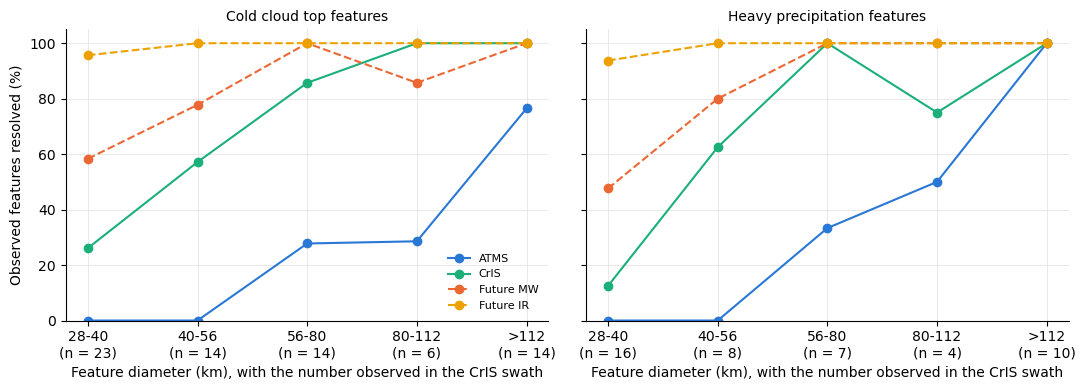

In [10]:
BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984", "#0b0b0b"
SENSOR_COLORS = {"ATMS": BLUE, "Future MW": ORANGE, "CrIS": AQUA, "Future IR": YELLOW}
SENSOR_STYLES = {"ATMS": "-", "Future MW": "--", "CrIS": "-", "Future IR": "--"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})

edges = np.array([EFFECTIVE_RESOLUTION_KM, 40, 56, 80, 112, np.inf])
labels = [f"{EFFECTIVE_RESOLUTION_KM}-40", "40-56", "56-80", "80-112", ">112"]
results["size_class"] = pd.cut(results.diameter_km, edges, labels=labels, right=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, kind in zip(axes, KINDS):
    of_kind = results[results.kind == kind]
    observed = of_kind[of_kind.observed]
    by_size = observed.groupby(["sensor", "size_class"], observed=False).resolved.mean().unstack().loc[sensors.index] * 100
    for sensor in sensors.index:
        ax.plot(labels, by_size.loc[sensor], marker="o", color=SENSOR_COLORS[sensor], ls=SENSOR_STYLES[sensor], label=sensor)
    counts = observed[observed.sensor == "CrIS"].groupby("size_class", observed=False).size()
    ax.set_xticks(range(len(labels)), [f"{label}\n(n = {n})" for label, n in zip(labels, counts)])
    ax.set(xlabel="Feature diameter (km), with the number observed in the CrIS swath", title=f"{kind.capitalize()} features", ylim=(0, 105))
    ax.title.set_fontsize(10)
axes[0].set_ylabel("Observed features resolved (%)")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

The figure shows, by size, the share of the observed features that each sensor resolves (in contrast to the monsoon OSSE, of the features observed rather than of all features, so that it shows resolution alone). The sensors differ most for the smallest features (28 to 56 km), which ATMS does not resolve at all and a future infrared sounder nearly always resolves, and least for those larger than 112 km, which every sensor resolves except where ATMS views only part of them at the edge of its swath. The counts per size class are small (4 to 23 features), so the shares of a class are uncertain by tens of percentage points.

## Limitations

The limitations of the monsoon OSSE apply, notably that resolution is geometric (without the response of each footprint), that the future sensors are assumed to share the swaths and platforms of ATMS and CrIS, and that features are snapshots. In addition:

* **One storm, two days.** The results describe one simulated storm at one stage of its life, sampled by one realization of the satellites' passes. Other storms, stages, and dates (extend `start` and `duration`, or find other storms in the coarsened Nature Run) would be needed for statistics.
* **The study region is fitted to the storm.** Features of the storm's environment are counted only within the box around its track, so their number depends on the box.
* **The storm center is coarse.** The center is the minimum sea-level pressure of the 0.5 degree, hourly collection, interpolated to the frames, so it is uncertain by tens of kilometers, which matters little for the 500 km radius that attributes features to the storm.
* **The features are proxies.** Cold cloud tops and heavy precipitation identify where observations may be valuable; the quantities a sounder retrieves in a hurricane (the warm core, the temperature and humidity of its environment, the rain and ice of its rainbands) depend on its channels, and infrared sounders do not see beneath the cloud tops.
* **The Nature Run is not reality.** Its storm is simulated at 7 km, which does not resolve the eyewall of a strong hurricane, so its smallest features (and the precipitation rates within them) differ from those of a real storm.